# SDR-ToF Notebook

## Overview
This notebook processes USRP Software Defined Radio (SDR) captures to extract phase information and convert it to audio. It implements a digital Phase-Locked Loop (PLL) for phase tracking and demonstrates continuous wave time-of-flight (ToF) ranging principles.

## Environment Requirements
- **Python 3.8+**
- **Core Libraries**: NumPy, SciPy, Matplotlib
- **SDR/DSP**: UHD (USRP Hardware Driver) for data acquisition - not required for analysis
- **Audio**: SoundDevice, SciPy (for WAV I/O)
- **Jupyter**: ipympl (for interactive widget plots)
- **Custom Module**: `IQ_Filter` (included in project)

## Notebook Structure
1. **Data Loading & Preprocessing**: Load USRP sc16 IQ samples, skip transient, estimate tone frequency
2. **Filtering & Decimation**: Apply HPF/LPF and decimate from 10 MSPS to 156.25 kHz
3. **Phase Tracking**: Implement a second-order PLL to lock onto phase drift
4. **Range Calculation**: Convert phase noise to ranging error (mm-level resolution)
5. **Spectral Analysis**: FFT of phase data to identify noise/signal components
6. **Audio Synthesis**: Convert phase readout to audible waveform and save as WAV file

## Key Parameters
- **Sample Rate**: 10 MSPS (RX), decimated to 156.25 kHz
- **Center Frequency**: 900 MHz (adjust as needed)
- **Baseband Tone**: 10 kHz
- **PLL Loop Bandwidth**: 5 Hz (filters physical signals >5 Hz)
- **Lock Time**: 1 second (discard during analysis)

# Data read
1. Edit Fs, Fc, Fb: Depending on how the SDR is configured to generate data
2. Select times for skipping and plotting [plot only a few seconds (0.5) to sanity check the IQ structure and not overwhelm the plotting functions]
3. store x [complex64] IQ signal.

## Data collection strategy
1. First 0.5 seconds is idle for throwing away pipelined samples
2. Next 1 second idle for lock acquisition - if using PLL

Note: We could only provide a small snapshot of data within the upload limits. Full dataset will be made available upon request and also be made public after peer review.

In [ ]:
#!/usr/bin/env python3
import json
from pathlib import Path

import ipympl
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

%matplotlib widget
%load_ext autoreload
%autoreload 2

plt.close('all')

# -----------------------
# Capture selection
# -----------------------
# Option 1: point directly to a metadata JSON file
manifest_path = None

# Option 2: point to a directory and auto-pick the newest run_metadata_*.json
capture_dir = Path("./May03")

# -----------------------
# Analysis settings
# -----------------------
seconds_to_plot = 8.5
skip_seconds = 0.25
max_samples = None

# DDC settings
remove_dc_after_ddc = False
use_estimated_fb = False

# Plotting
plotRawIQ_constln = False
plotIQ_time = False
plotDDC_IQ = True
plot_phase = True


def pick_manifest(manifest_path=None, capture_dir=None):
    if manifest_path is not None:
        path = Path(manifest_path)
        if not path.exists():
            raise FileNotFoundError(f"Manifest not found: {path}")
        return path

    if capture_dir is None:
        raise ValueError("Provide manifest_path or capture_dir.")

    capture_dir = Path(capture_dir)
    manifests = sorted(capture_dir.glob("run_metadata_*.json"), key=lambda p: p.stat().st_mtime)
    if not manifests:
        raise FileNotFoundError(f"No run_metadata_*.json files found in {capture_dir}")
    return manifests[-1]


def load_run_manifest(manifest_path):
    manifest_path = Path(manifest_path)
    with manifest_path.open("r", encoding="utf-8") as f:
        meta = json.load(f)

    files = meta.get("files", {})
    requested = meta.get("requested", {})
    applied = meta.get("applied", {})
    capture = meta.get("capture", {})
    rx_stats = meta.get("rx_stats", {})
    tx_stats = meta.get("tx_stats", {})

    iq_file = Path(files["iq_bin"])
    rx_events_csv = files.get("rx_events_csv")
    rx_events_csv = None if rx_events_csv in (None, "", "null") else Path(rx_events_csv)

    fs = float(applied.get("sample_rate_sps", requested.get("sample_rate_sps")))
    fc = float(applied.get("rx_center_freq_hz", requested.get("rx_center_freq_hz")))
    fb = float(requested.get("tx_tone_freq_hz"))

    return {
        "manifest_path": manifest_path,
        "manifest": meta,
        "iq_file": iq_file,
        "rx_events_csv": rx_events_csv,
        "fs": fs,
        "fc": fc,
        "fb": fb,
        "requested": requested,
        "applied": applied,
        "capture": capture,
        "rx_stats": rx_stats,
        "tx_stats": tx_stats,
    }


def print_capture_summary(run_cfg):
    print(f"Manifest: {run_cfg['manifest_path']}")
    print(f"IQ file:   {run_cfg['iq_file']}")
    print(f"RX events: {run_cfg['rx_events_csv']}")
    print(
        f"fs={run_cfg['fs']:.3f} Hz, fc={run_cfg['fc']:.3f} Hz, fb={run_cfg['fb']:.3f} Hz"
    )
    print(
        "TX stats:",
        run_cfg["tx_stats"],
    )
    print(
        "RX stats:",
        run_cfg["rx_stats"],
    )


def block_average(v, N):
    """Block-average v in non-overlapping blocks of size N."""
    L = (len(v) // N) * N
    v2 = v[:L].reshape(-1, N)
    return v2.mean(axis=1)


def block_mid_times(num_blocks, N, fs):
    """Time at the center of each block."""
    idx = (np.arange(num_blocks) * N) + (N / 2)
    return idx / fs


def load_rx_events_csv(rx_events_csv_path):
    """Optional RX event log written by the capture app."""
    if rx_events_csv_path is None:
        return None

    rx_events_csv_path = Path(rx_events_csv_path)
    if not rx_events_csv_path.exists():
        print(f"RX event CSV not found: {rx_events_csv_path}")
        return None

    data = np.genfromtxt(rx_events_csv_path, delimiter=",", names=True, dtype=None, encoding=None)
    if getattr(data, "size", 0) == 0:
        return {
            "seq": np.array([], dtype=np.int64),
            "nsamps": np.array([], dtype=np.int64),
            "has_time": np.array([], dtype=np.int64),
            "time_full": np.array([], dtype=np.int64),
            "time_frac": np.array([], dtype=np.float64),
            "err_code": np.array([], dtype=np.int64),
            "num_blocks": 0,
            "total_samps_logged": 0,
            "num_err": 0,
        }

    data = np.atleast_1d(data)
    meta = {
        "seq": np.asarray(data["seq"], dtype=np.int64),
        "nsamps": np.asarray(data["nsamps"], dtype=np.int64),
        "has_time": np.asarray(data["has_time"], dtype=np.int64),
        "time_full": np.asarray(data["time_full"], dtype=np.int64),
        "time_frac": np.asarray(data["time_frac"], dtype=np.float64),
        "err_code": np.asarray(data["err_code"], dtype=np.int64),
    }
    meta["num_blocks"] = int(meta["seq"].size)
    meta["total_samps_logged"] = int(np.sum(meta["nsamps"]))
    meta["num_err"] = int(np.sum(meta["err_code"] != 0))
    return meta


# -----------------------
# Helper: robust IQ loader (USRP sc16)
# -----------------------
def load_usrp_sc16_as_complex64(iq_file_path, max_samples=None, normalize=True):
    """
    UHD sc16: interleaved int16 IQ: [I0,Q0,I1,Q1,...]
    Returns complex64 normalized to ~[-1,1) if normalize=True.
    """
    raw = np.fromfile(iq_file_path, dtype=np.int16)
    if raw.size < 2:
        raise ValueError("File too short to contain IQ data.")
    if raw.size % 2 != 0:
        raw = raw[:-1]

    iq = raw.reshape(-1, 2)
    I = iq[:, 0].astype(np.float32)
    Q = iq[:, 1].astype(np.float32)

    if normalize:
        x = (I + 1j * Q) / 32768.0
    else:
        x = I + 1j * Q

    x = x.astype(np.complex64)
    if max_samples is not None:
        x = x[:max_samples]
    return x


# -----------------------
# Helper: frequency estimate
# -----------------------
def estimate_tone_freq(x, fs, nfft=2**18):
    """Estimate dominant tone frequency using FFT peak."""
    n = min(len(x), nfft)
    xw = x[:n] * np.hanning(n)
    X = np.fft.fftshift(np.fft.fft(xw))
    f = np.fft.fftshift(np.fft.fftfreq(n, d=1 / fs))
    k = np.argmax(np.abs(X))
    return float(f[k])


run_cfg = load_run_manifest(pick_manifest(manifest_path=manifest_path, capture_dir=capture_dir))
print_capture_summary(run_cfg)

manifest = run_cfg["manifest"]
iq_file = run_cfg["iq_file"]
meta_blocks = load_rx_events_csv(run_cfg["rx_events_csv"])
fs = run_cfg["fs"]
fc = run_cfg["fc"]
fb = run_cfg["fb"]

if meta_blocks is not None:
    print(
        f"Meta blocks: {meta_blocks['num_blocks']}, "
        f"total_samps_logged={meta_blocks['total_samps_logged']}, "
        f"nonzero_err_blocks={meta_blocks['num_err']}"
    )
else:
    print("No RX event CSV for this run; relying on JSON manifest only.")


# -----------------------
# Load IQ
# -----------------------
x = load_usrp_sc16_as_complex64(iq_file, max_samples=max_samples, normalize=True)
N0 = len(x)
print(f"Loaded {N0} complex samples ({N0 / fs:.3f} s) from {iq_file}")

manifest_written = manifest.get("capture", {}).get("rx_samples_written")
if manifest_written is not None:
    diff = N0 - int(manifest_written)
    print(f"Sample count CHECK: file - manifest = {diff} samples")

if meta_blocks is not None and meta_blocks["total_samps_logged"] > 0:
    diff_meta = N0 - meta_blocks["total_samps_logged"]
    print(f"Sample count CHECK: file - rx_events_sum = {diff_meta} samples")


# -----------------------
# Skip initial transient
# -----------------------
skip = int(skip_seconds * fs)
if skip >= N0:
    raise ValueError("skip_seconds is too large for the file length.")
x = x[skip:]
N = len(x)
print("After skip:", N, "samples;", N / fs, "s")

fb_hat = estimate_tone_freq(x, fs)

if use_estimated_fb:
    print(f"Estimated tone frequency: {fb_hat:.4f} Hz")
    fb_used = fb_hat
else:
    fb_used = fb
    print(f"Estimated frequency (sanity): {fb_hat:.4f} Hz")
    print(f"Using fb from metadata JSON: {fb_used:.3f} Hz")

M = int(seconds_to_plot * fs)
M = min(M, N)
t = np.arange(M) / fs

if plotIQ_time:
    plt.figure(figsize=(5, 5))
    ds = 10
    plt.plot(t[::ds] * 1e3, np.real(x[:M][::ds]), label="I (real)")
    plt.plot(t[::ds] * 1e3, np.imag(x[:M][::ds]), label="Q (imag)")
    plt.xlabel("Time (ms)")
    plt.ylabel("Amplitude")
    plt.title("Raw RX IQ")
    plt.legend()
    plt.grid(True)
    plt.show()

if plotRawIQ_constln:
    plt.figure(figsize=(5, 5))
    plt.scatter(np.real(x[:M]), np.imag(x[:M]), s=4, alpha=0.5)
    plt.xlabel("I")
    plt.ylabel("Q")
    plt.title("Raw IQ (from RX samples)")
    plt.grid(True)
    plt.axis("equal")
    plt.show()


# Observe the phase std_dev
n = np.arange(N, dtype=np.float64)
lo = np.exp(-1j * 2.0 * np.pi * fb_used * n / fs).astype(np.complex64)
y = x * lo

y_seg = y[:M]
phi_raw = np.angle(y_seg)

phi_std = np.std(phi_raw)
phi_mean = np.mean(phi_raw)
print(f"Mean and std dev of measured phase (raw, first {M / fs:.3f} s): {phi_mean:.6f}, {phi_std:.6f}")


# Downconvert the raw IQ signal to DC
1. Filter the raw IQ to include Fb and maximum phase shift expected: 20 kHz (instrument bandwidth)
2. Downconvert from 10 msps to 78.125 kHz with factors [8,4,4] -> other sampling rates - downconvert appropriately
3. Use LPF to cutoff at 25 kHz with a transition width of 5 kHz. 3 dB attenuation occurs at nearly 25 kHz.

Decimation factors: [8, 4, 2], final Fs: 156250.0 Hz
--- Decimation chain start: Fs=10.000 MSPS ---
Stage 1: / 8 |   10000.0 kHz ->    1250.0 kHz | taps=109
Stage 2: / 4 |    1250.0 kHz ->     312.5 kHz | taps=63
Stage 3: / 2 |     312.5 kHz ->     156.2 kHz | taps=39
--- Decimation chain end: Fs=156.250 kSPS ---


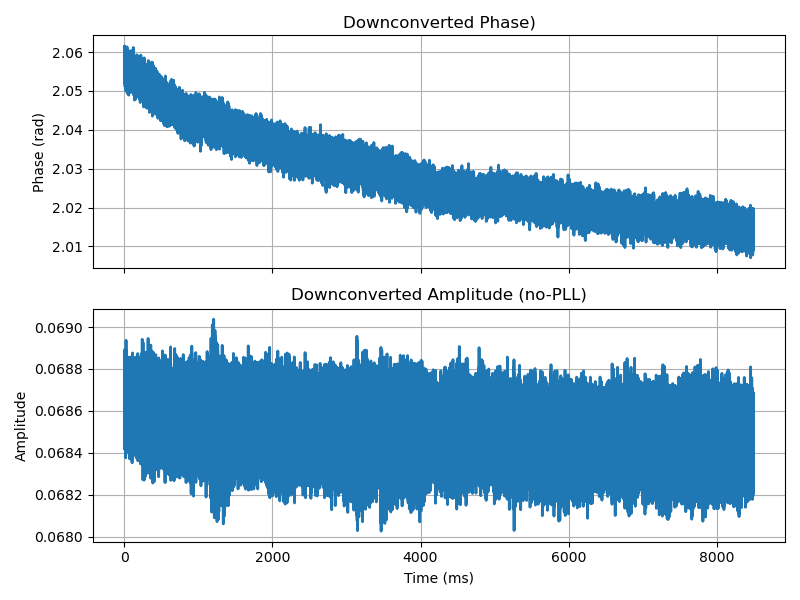

Mean and std dev of measured phase (raw, first 8.500 s): 2.028247, 0.010823


In [2]:
# -----------------------
# FILTERING
# -----------------------
import IQ_Filter

SIG = x

# Digital filter design
FS_INPUT = fs
FS_INSTRUMENT = FS_INPUT
BW_MEASUREMENT = 20e3
HPF_CUTOFF = 20.0      # PLL does high pass action
LPF_TRANSITION_BW = 5000

# 10 MSPS -> 1.25 MHz -> 312.5 kHz -> 156.25 kHz
factors = [8,4,2]

for f in factors:
    FS_INSTRUMENT /= f
print(f"Decimation factors: {factors}, final Fs: {FS_INSTRUMENT} Hz")

x_filt, Fs_decim = IQ_Filter.IQ_filter(
    SIG,
    FS_INPUT,
    FS_INSTRUMENT,
    BW_MEASUREMENT,
    HPF_CUTOFF,
    LPF_TRANSITION_BW,
    DECIM_FACTORS=factors,
)

N = len(x_filt)

# -----------------------
# Plot filtered amplitude (time domain)
# -----------------------

Md = int(seconds_to_plot * Fs_decim)
Md = min(Md, N)
t_decim = np.arange(Md) / Fs_decim

n = np.arange(Md, dtype=np.float64)
lo = np.exp(-1j * 2.0 * np.pi * fb_used * n / Fs_decim).astype(np.complex64)
y_filt = x_filt[:Md] * lo
phase_npll = (np.angle(y_filt))
amp_npll = np.abs(y_filt)

plt.close('all')

plot_phase = True
if plot_phase:
    fig, ax = plt.subplots(2, 1, sharex=True, figsize=(8, 6))
    ds = 1
    ax[0].plot(t_decim[:Md][::ds] * 1e3, phase_npll[:Md][::ds], linewidth=2.0) # could also use corrected_phase[ss_id:]
    ax[0].set_ylabel("Phase (rad)")
    ax[0].set_title("Downconverted Phase)")
    ax[0].grid(True)

    ax[1].plot(t_decim[:Md][::ds] * 1e3, amp_npll[:Md][::ds], linewidth=2.0)
    ax[1].set_xlabel("Time (ms)")
    ax[1].set_ylabel("Amplitude")
    ax[1].set_title("Downconverted Amplitude (no-PLL)")
    ax[1].grid(True)

    plt.tight_layout()
    plt.show()


phi_std  = np.std(phase_npll)
phi_mean = np.mean(phase_npll)
print(f"Mean and std dev of measured phase (raw, first {M/fs:.3f} s): {phi_mean:.6f}, {phi_std:.6f}")

# Phase Readout
1. Send the filtered, downconverted IQ signal to the PLL loop
2. Select PLL loopbandwidth = 5 Hz; settling time ~ 3/BW ~ 0.6 seconds. Select t_lock = 1 second for lock acquistion - need not analyze this signal. 
3. Using the correct Fb = 10 kHz - PLL locks on to remove the drift in the IQ signal.
4. Readout the correct IQ signal or phase directly.

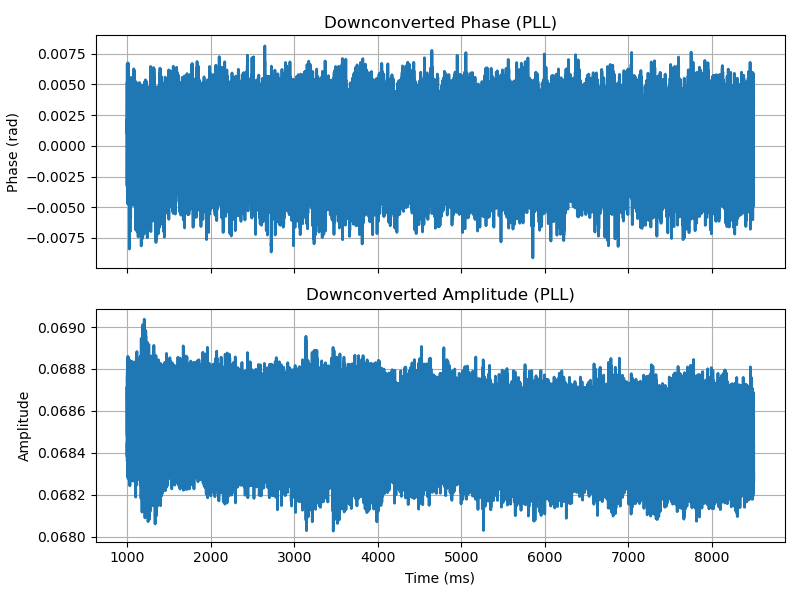

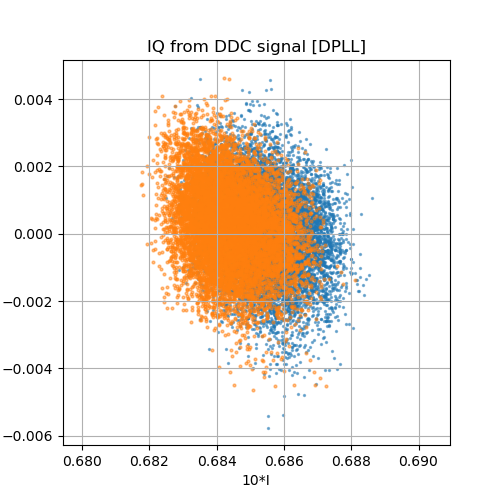

Mean and std dev of measured phase (filtered-PLL): -0.000020, 0.001931


In [3]:
loop_BW = 5 # Hz
t_lock = 1 # Seconds

def process_phase_pll(x, F_decim, fb, loop_bw=1.0):
    """
    x: Input complex samples from USRP
    F_decim: Decimated sample rate
    fb_100khz: Your baseband IF
    loop_bw: Loop bandwidth in Hz (set low to avoid eating your 60Hz signal)
    """
    N = len(x)
    y_corrected = np.zeros(N, dtype=np.complex64)
    phase_out = np.zeros(N)
    
    # 1. Design Loop Constants (Damping factor zeta = 0.707)
    # We want to track the drift but NOT the 60Hz+ signals. -> Physical phase signal
    # Set loop_bw to ~5Hz to safely ignore your 60Hz physical signal.
    theta = loop_bw / F_decim
    zeta = 0.707
    alpha = (4 * zeta * theta) / (1 + 2 * zeta * theta + theta**2)
    beta = (4 * theta**2) / (1 + 2 * zeta * theta + theta**2)
    
    # 2. Initialize Loop Variables
    integrator = 0.0
    phase_estimate = 0.0
    
    # 3. Processing Loop
    for n in range(N):
        # Generate LO with current phase correction
        # We add the nominal 100kHz rotation + the PLL correction
        lo_phase = 2.0 * np.pi * fb * n / F_decim + phase_estimate
        lo = np.exp(-1j * lo_phase)
        
        # Downconvert
        sample_dc = x[n] * lo
        y_corrected[n] = sample_dc
        
        # Calculate Phase Error (Approximation of sin(delta_phi))
        # This keeps the signal locked to the Real axis (Phase = 0)
        error = np.imag(sample_dc / np.abs(sample_dc)) if np.abs(sample_dc) > 0 else 0
        
        # Update Loop Filter (PI Controller)
        integrator += beta * error
        phase_estimate += alpha * error + integrator
        
        # Record the "Physical Phase"
        # Since the loop is tracking the drift to 0, 
        # the 'error' or the instantaneous angle of y_corrected 
        # contains your high-frequency physical data.
        phase_out[n] = np.angle(sample_dc)
        
    return y_corrected, phase_out

# Example Usage: Plotting Md samples
y_corr, corrected_phase = process_phase_pll(x_filt[:Md], Fs_decim, fb, loop_BW)

ss_id = int(t_lock * Fs_decim) # steady state sample index
y_ssid = y_corr[ss_id:]
if t_decim.size == 0:
    print("Warning: t_decim is empty; t_lock will take 1.0 second, plot more seconds.")
    t_ssid = np.array([], dtype=float)
else:
    t_ssid = t_decim[ss_id:]


ss_phase = np.unwrap(np.angle(y_ssid))
ss_amp = np.abs(y_ssid)

plt.close('all')
if plot_phase:
    fig, ax = plt.subplots(2, 1, sharex=True, figsize=(8, 6))
    ax[0].plot(t_ssid * 1e3, ss_phase, linewidth=2.0) # could also use corrected_phase[ss_id:]
    ax[0].set_ylabel("Phase (rad)")
    ax[0].set_title("Downconverted Phase (PLL)")
    ax[0].grid(True)

    ax[1].plot(t_ssid * 1e3, ss_amp, linewidth=2.0)
    ax[1].set_xlabel("Time (ms)")
    ax[1].set_ylabel("Amplitude")
    ax[1].set_title("Downconverted Amplitude (PLL)")
    ax[1].grid(True)

    plt.tight_layout()
    plt.show()

if plotDDC_IQ:
    plt.figure(figsize=(5, 5))
    plt.scatter(10*np.real(y_ssid[:10000]), 10*np.imag(y_ssid[:10000]), s=2, alpha=0.5)
    plt.scatter(10*np.real(y_ssid[-10000:]), 10*np.imag(y_ssid[-10000:]), s=4, alpha=0.5)
    plt.xlabel("10*I")
    plt.ylabel("10*Q")
    plt.title("IQ from DDC signal [DPLL]")
    plt.grid(True)
    plt.axis('equal')
    plt.show()

phi_std  = np.std(ss_phase)
phi_mean = np.mean(ss_phase)
print(f"Mean and std dev of measured phase (filtered-PLL): {phi_mean:.6f}, {phi_std:.6f}")

# Range and Resolution
Disambiguous range and resolution

In [10]:
import numpy as np 
fc_tx = fc + fb
c = 299_792_458.0

lam = c / fc_tx
dphi_std = .1
dR_calib = dphi_std * lam / (4 * np. pi)

print(f"For a measured phi of: {dphi_std*1e3} mrad, expect a ranging error of: {dR_calib*1e3}mm")

For a measured phi of: 100.0 mrad, expect a ranging error of: 2.6507178582665434mm


# Spectral analysis of phase data

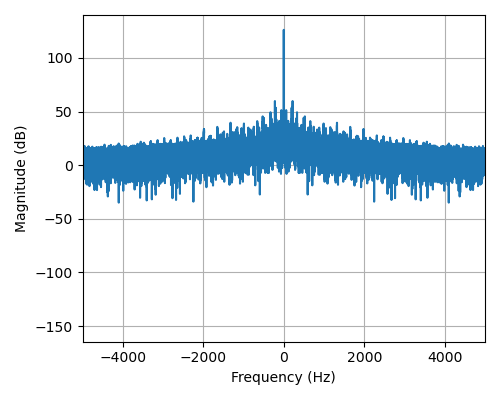

In [5]:
def plot_fft(x, fs, f_center, title, fspan=None):
    x = np.asarray(x)
    # x = x - np.mean(x)

    N = len(x)
    win = np.hanning(N)
    X = np.fft.fftshift(np.fft.fft(x * win)) 
    f = np.fft.fftshift(np.fft.fftfreq(N, d=1/fs))
    
    # X = np.fft.rfft(x * win) 
    # f = np.fft.rfftfreq(N, 1/fs)

    mag = 20 * np.log10(np.maximum(np.abs(X), 1e-12))

    plt.figure(figsize=(5, 4))
    plt.plot(f, mag)
    plt.grid(True)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude (dB)")
    plt.title(title)

    if fspan is not None:
        plt.xlim(f_center - fspan, f_center + fspan)

    plt.tight_layout()
    plt.show()

plot_fft(x=phase_npll, fs=Fs_decim, f_center = 0, title=None, fspan=5e3)

# Phase to raw audio
1. Phase is obtained with a sample rate of 156.25 kHz but filtered everything below 20 kHz
2. Construct audio from phase: filter with additional cutoff if needed
3. Choose phi2audio = ss_phi to reconstruction audio from phase | ss_amp to get audio from amplitude
4. Select lpf frequency, hpf frequency, mode in phase2audio(): ifreq from derivative of phase | phase 

In [ ]:
import sounddevice as sd
from scipy.signal import resample_poly, butter, filtfilt
from scipy.io.wavfile import write as wavwrite
from pathlib import Path

parent_path = Path("./Apr23/")

fs2audio = Fs_decim
phi2audio = ss_phase
# phi2audio = ss_amp

audio_fname = "journey_1"

def save_wav(filename, x_audio, fs):
    """
    Save audio to WAV file.
    x_audio must be float32 in [-1, 1].
    """
    # Convert to 16-bit PCM for compatibility
    x_int16 = np.int16(np.clip(x_audio, -1.0, 1.0) * 32767)
    wavwrite(filename, fs, x_int16)

    # Bandlimit into an audio-friendly band
    # High-pass removes drift; low-pass removes HF noise
def butter_filt(sig, fs, btype, cutoff_hz, order=4):
    nyq = 0.5 * fs
    wn = cutoff_hz / nyq
    b, a = butter(order, wn, btype=btype)
    return filtfilt(b, a, sig)

def phase_to_audio(
    phi,
    fs_phi,
    audio_fs,
    mode="phase",          # "phase" or "ifreq"
    hp_hz=60.0,            # high-pass to remove drift / DC in phase or ifreq
    lp_hz=10000.0,          # low-pass to keep audio band reasonable
    gain=0.9,              # overall volume scaling (0..1 typical)
    speed=1.0              # time-stretch: >1 faster/higher pitch, <1 slower/lower pitch
):
    """
    Convert phase readout to an audio waveform (float32 in [-1,1]).
    phi: phase samples in radians (preferably unwrapped)
    fs_phi: sample rate of phi (Hz)
    audio_fs: playback sample rate (Hz)
    mode:
      - "phase": listen to phase variation (after HP/LP)
      - "ifreq": listen to instantaneous frequency variation (dphi/dt), often clearer
    speed: playback speed factor (pitch shifts accordingly)
    """
    phi = np.asarray(phi, dtype=np.float64)

    # Handle unwrap if user forgot (safe)
    phi = np.unwrap(phi)

    # Remove mean (helps a lot)
    phi = phi - np.mean(phi)

    if mode.lower() == "ifreq":
        # Instantaneous frequency deviation proportional to derivative of phase:
        # dphi/dt / (2*pi)  -> Hz deviation (but we don't need absolute units for audio)
        x = np.diff(phi, prepend=phi[0]) * fs_phi / (2 * np.pi)
        fs_x = fs_phi
    elif mode.lower() == "phase":
        x = phi.copy()
        fs_x = fs_phi
    else:
        raise ValueError("mode must be 'phase' or 'ifreq'")

    # Optional time scaling (speed change)
    # Implement by resampling the signal in time
    if speed != 1.0 and speed > 0:
        # Speed up => fewer samples (higher pitch), slow down => more samples
        # resample_poly expects integer factors; approximate with rational
        # We'll do a simple resample using interpolation ratio
        n_new = int(len(x) / speed)
        n_new = max(n_new, 2)
        x = np.interp(
            np.linspace(0, len(x) - 1, n_new),
            np.arange(len(x)),
            x
        )
        fs_x = fs_x  # fs_x unchanged; we changed duration directly

    if hp_hz is not None and hp_hz > 0:
        x = butter_filt(x, fs_x, "highpass", hp_hz)

    if lp_hz is not None and lp_hz > 0 and lp_hz < 0.49 * fs_x:
        x = butter_filt(x, fs_x, "lowpass", lp_hz)

    # Resample to audio_fs
    # Use polyphase rational resampling (good quality)
    # Find integer up/down approximately (simple approach)
    # If fs_x is huge, this is still efficient.
    from math import gcd
    up = int(audio_fs)
    down = int(fs_x)
    g = gcd(up, down)
    up //= g
    down //= g
    x_audio = resample_poly(x, up, down)

    # Normalize to [-1, 1] and apply gain
    peak = np.max(np.abs(x_audio)) + 1e-12
    x_audio = (x_audio / peak) * gain
    x_audio = x_audio.astype(np.float32)

    return x_audio, audio_fs

def play_audio(x_audio, fs):
    sd.stop()
    sd.play(x_audio, fs, blocking=True)


# Listen to instantaneous frequency (usually more “audio-like”)
x_audio, audio_fs = phase_to_audio(
    phi = ss_phase,      # Use phi_clean, not undefined phi_hp
    fs_phi = fs2audio,
    audio_fs = Fs_decim,     # Standard audio sample rate (or fs2audio if already 48k)
    mode = "phase",       # Velocity sounds more natural than displacement
    hp_hz = 0.0,         # Only remove DC/subsonic
    lp_hz = None,         # Don't double-filter
    gain = 0.95,
    speed = 1.0
)

# plot_fft(
#     x_audio,        # real or imag are equivalent here
#     fs2audio,
#     f_center=0.0,
#     title=f"FFT: phase (fs_final={fs2audio:.1f} Hz)",
#     fspan=10e3   # e.g. inspect up to 2 kHz around DC
# )   


parent_path.mkdir(parents=True, exist_ok=True)
# suffix =  str(meta_file).split("/")[-1].split("_")[2]

save_wav(parent_path / f"{audio_fname}.wav", x_audio, int(fs2audio))

In [6]:
import numpy as np
import sounddevice as sd
from scipy.signal import butter, filtfilt, resample_poly, iirnotch
from scipy.io.wavfile import write as wavwrite
from scipy import signal
from pathlib import Path
from math import gcd

parent_path = Path("./Mar19/")
audio_fname = "interstellar_audio_clean"

# ---------------------------------------------------------
# WAV save
# ---------------------------------------------------------
def save_wav(filename, x_audio, fs):
    x_audio = np.asarray(x_audio, dtype=np.float32)
    x_int16 = np.int16(np.clip(x_audio, -1.0, 1.0) * 32767)
    wavwrite(str(filename), fs, x_int16)

# ---------------------------------------------------------
# Filters
# ---------------------------------------------------------
def butter_filt(sig, fs, btype, cutoff_hz, order=4):
    sig = np.asarray(sig, dtype=np.float64)
    nyq = 0.5 * fs

    if np.isscalar(cutoff_hz):
        wn = cutoff_hz / nyq
    else:
        wn = [c / nyq for c in cutoff_hz]

    b, a = butter(order, wn, btype=btype)
    return filtfilt(b, a, sig)

def notch_filter(sig, fs, f0, Q=30):
    b, a = iirnotch(w0=f0, Q=Q, fs=fs)
    return filtfilt(b, a, sig)

# ---------------------------------------------------------
# Simple spectral gating for hiss reduction
# ---------------------------------------------------------
def spectral_gate(
    x,
    fs,
    nperseg=1024,
    noverlap=768,
    noise_seconds=0.5,
    gate_strength=2.0,
    floor_ratio=0.15
):
    """
    Estimate stationary noise from the first `noise_seconds` of audio
    and attenuate STFT bins below threshold.
    """
    x = np.asarray(x, dtype=np.float64)

    f, t, Zxx = signal.stft(
        x, fs=fs, window="hann", nperseg=nperseg, noverlap=noverlap, boundary=None
    )
    mag = np.abs(Zxx)
    phase = np.angle(Zxx)

    # Estimate noise profile from first few frames
    frames_for_noise = max(1, int(noise_seconds * fs / (nperseg - noverlap)))
    noise_mag = np.median(mag[:, :frames_for_noise], axis=1, keepdims=True)

    # Threshold
    thresh = gate_strength * noise_mag

    # Soft mask instead of hard cutoff
    mask = mag / (mag + thresh + 1e-12)
    mask = np.maximum(mask, floor_ratio)

    Zxx_denoised = mask * mag * np.exp(1j * phase)
    _, x_rec = signal.istft(
        Zxx_denoised, fs=fs, window="hann", nperseg=nperseg, noverlap=noverlap,
        input_onesided=True, boundary=None
    )

    # Match original length
    if len(x_rec) > len(x):
        x_rec = x_rec[:len(x)]
    elif len(x_rec) < len(x):
        x_rec = np.pad(x_rec, (0, len(x) - len(x_rec)))

    return x_rec

# ---------------------------------------------------------
# Robust normalization
# ---------------------------------------------------------
def robust_normalize(x, gain=0.95, percentile=99.5):
    x = np.asarray(x, dtype=np.float64)
    scale = np.percentile(np.abs(x), percentile) + 1e-12
    x = x / scale
    x = np.clip(x * gain, -1.0, 1.0)
    return x.astype(np.float32)

# ---------------------------------------------------------
# Main conversion
# ---------------------------------------------------------
def phase_to_audio_clean(
    phi,
    fs_phi,
    audio_fs=48000,
    mode="ifreq",              # "phase" or "ifreq"
    hp_hz=80.0,
    lp_hz=6000.0,
    bandpass=None,             # e.g. (120, 4500)
    speed=1.0,
    remove_hum=True,
    hum_freq=60.0,
    denoise=True,
    gain=0.95
):
    phi = np.asarray(phi, dtype=np.float64)

    # unwrap and center
    phi = np.unwrap(phi)
    phi = phi - np.mean(phi)

    # linear detrend helps reduce low-frequency wander
    phi = signal.detrend(phi, type="linear")

    if mode.lower() == "ifreq":
        # instantaneous frequency deviation
        x = np.diff(phi, prepend=phi[0]) * fs_phi / (2 * np.pi)
    elif mode.lower() == "phase":
        x = phi.copy()
    else:
        raise ValueError("mode must be 'phase' or 'ifreq'")

    fs_x = fs_phi

    # Optional speed change by time resampling before audio conversion
    if speed != 1.0 and speed > 0:
        n_new = max(2, int(len(x) / speed))
        x = np.interp(
            np.linspace(0, len(x) - 1, n_new),
            np.arange(len(x)),
            x
        )

    # Filtering
    if bandpass is not None:
        x = butter_filt(x, fs_x, "bandpass", bandpass, order=4)
    else:
        if hp_hz is not None and hp_hz > 0:
            x = butter_filt(x, fs_x, "highpass", hp_hz, order=4)
        if lp_hz is not None and lp_hz < 0.49 * fs_x:
            x = butter_filt(x, fs_x, "lowpass", lp_hz, order=4)

    # Remove mains hum if present
    if remove_hum:
        for k in [1, 2, 3]:
            f0 = hum_freq * k
            if f0 < 0.45 * fs_x:
                x = notch_filter(x, fs_x, f0, Q=35)

    # Resample to standard audio rate
    up = int(audio_fs)
    down = int(fs_x)
    g = gcd(up, down)
    up //= g
    down //= g
    x_audio = resample_poly(x, up, down)

    # Hiss reduction after audio-rate conversion
    if denoise:
        x_audio = spectral_gate(
            x_audio,
            fs=audio_fs,
            nperseg=1024,
            noverlap=768,
            noise_seconds=0.4,
            gate_strength=1.8,
            floor_ratio=0.12
        )

    # Gentle final audio band-limit
    x_audio = butter_filt(x_audio, audio_fs, "highpass", 40.0, order=2)
    x_audio = butter_filt(x_audio, audio_fs, "lowpass", min(8000.0, 0.45 * audio_fs), order=2)

    # Robust normalization
    x_audio = robust_normalize(x_audio, gain=gain, percentile=99.5)

    return x_audio, audio_fs

def play_audio(x_audio, fs):
    sd.stop()
    sd.play(x_audio, fs, blocking=True)


parent_path.mkdir(parents=True, exist_ok=True)

x_audio, audio_fs = phase_to_audio_clean(
    phi=ss_phase,
    fs_phi=Fs_decim,
    audio_fs=48000,
    mode="ifreq",          # try "ifreq" first; usually cleaner than raw phase
    hp_hz=100.0,
    lp_hz=5000.0,
    bandpass=None,         # or set bandpass=(150, 4000) for more voice/radio-like sound
    speed=1.0,
    remove_hum=True,
    hum_freq=60.0,
    denoise=True,
    gain=0.95
)

# play_audio(x_audio, audio_fs)
save_wav(parent_path / f"{audio_fname}.wav", x_audio, audio_fs)

/tmp/ipykernel_371768/2165953946.py:75: UserWarning: NOLA condition failed, STFT may not be invertible. Possibly due to missing boundary
  _, x_rec = signal.istft(


In [12]:
from math import gcd
from scipy.io.wavfile import write as wavwrite
import noisereduce as nr

SKIP_S = 1.0
WINDOW_S = 30.
skip  = int(SKIP_S * Fs_decim)
M_s   = int(WINDOW_S * Fs_decim)

AUDIO_FS = 48000 

phase_fir_noise = np.concatenate([ss_phase[:skip], ss_phase[skip + M_s:]])  # noise is the remainder of the signal after cropping
phase_fir_cropped = ss_phase[skip : skip + M_s]

def to_audio(sig, fs_in, fs_out=Fs_decim, gain=0.90):
    g = gcd(int(fs_out), int(fs_in))
    x = resample_poly(sig.astype(np.float64), fs_out // g, fs_in // g)
    peak = np.percentile(np.abs(x), 99.5) + 1e-12
    return np.clip(x / peak, -1.0, 1.0).astype(np.float32) * gain

phase_noise = to_audio(phase_fir_noise, Fs_decim)
phase_audio = to_audio(phase_fir_cropped, Fs_decim)  # resamples to AUDIO_FS=48000

# phase_audio = to_audio(phase_fir, FS_FINAL)
# static_audio = to_audio(phi_static_rad, FS_FINAL)

phi_denoised = nr.reduce_noise(
    y=phase_audio.astype(np.float64),
    sr=AUDIO_FS,
    stationary=False,
    y_noise=phase_noise.astype(np.float64),
    # y_noise=static_audio.astype(np.float64),
    prop_decrease=0.95,        # back off slightly from 1.0 to reduce artifacts
    n_std_thresh_stationary=1.0,
    freq_mask_smooth_hz=100,
    time_mask_smooth_ms=50,
    n_fft=4096,
)

phi_denoised = phi_denoised.astype(np.float32)
save_wav(parent_path / f'{audio_fname}_denoised_noisereduce.wav', phi_denoised, AUDIO_FS)
